In [98]:
# import sympy
from sympy import (symbols, expand, Rational, init_printing, sqrt, cos, sin,
                   init_printing, pprint, simplify, factor, trigsimp, collect,
                   cancel, powsimp, expand_power_exp, powdenest)
init_printing()

x, y, z = symbols("x y z")

expr = x + 2*y
e2 = 3*x + y**2
e3 = expr*e2*z
e4 = expand(e3)
# # print(e3)
# e4
# print((cos(x)+2).subs(cos(x), 3))


In [219]:
"""Calculations for m^-"""
x_0, y_0, theta0, x_c, y_c, r_c, rho, R, x_f, y_f, q = symbols(
    "x_0, y_0, theta0, x_c, y_c, r_c, rho, R, x_f, y_f, q")

# R = r_c + rho
# print(R)

c_0x = x_0 - rho*sin(theta0)
c_0y = y_0 + rho*cos(theta0)

cos1 = (1 - q**2)/(1 + q**2)
sin1 = 2*q/(1 + q**2)

c_1x = x_c - R*sin1
c_1y = y_c + R*cos1

m_minus_x = c_1x - c_0x
m_minus_x = collect(factor(m_minus_x), q)
m_minus_y = c_1y - c_0y
m_minus_y = collect(factor(m_minus_y),q)
# print("m_minus_x =", m_minus_x)
# print("m_minus_y =", m_minus_y)

m_d_minus = factor(m_minus_x**2 + m_minus_y**2)
m_d_minus = collect(m_d_minus, q)

# Simplify m_d_minus by regrouping some constant terms into subterms
m_d_minus_numer, m_d_minus_denom = m_d_minus.as_numer_denom()
# m_d_minus_numer
# m_d_minus_denom
# m_d_minus == m_d_minus_numer/m_d_minus_denom
c_mdm2, c_mdm1, c_mdm0 = symbols("c_mdm2, c_mdm1, c_mdm0")
c_md_min2 = m_d_minus_numer.coeff(q,2)
c_md_min1 = m_d_minus_numer.coeff(q,1)
c_md_min0 = m_d_minus_numer.coeff(q,0)
m_d_minus_numer = m_d_minus_numer - c_md_min2*q**2 - c_md_min1*q - c_md_min0 + c_mdm2*q**2 + c_mdm1*q + c_mdm0
# m_d_minus_numer
# c_md_min2
m_d_minus = m_d_minus_numer/m_d_minus_denom
# m_d_minus

# m_d_minus
# m_minus_x
# m_minus_y

# print(c_md_min2)
# print(c_md_min1)
# print(c_md_min0)

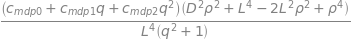

In [220]:
"""Calculations for m^+"""

# sin_thet, cos_thet, sin_delt, cos_delt = symbols("sin_thet, cos_thet, sin_delt, cos_delt")
L = sqrt( (c_1x - x_f)**2 + (c_1y - y_f)**2 )
L = expand(L)
L = symbols("L")
D = sqrt(L**2 - rho**2)
D = symbols('D')

sin_thet = D/L
# print(sin_thet)
cos_thet = rho/L
sin_delt = (y_f - c_1y)/L
# sin_delt = expand(sin_delt)
cos_delt = (x_f - c_1x)/L

x_R = c_1x + rho*(cos_delt*cos_thet + sin_delt*sin_thet)
y_R = c_1y + rho*(sin_delt*cos_thet - cos_delt*sin_thet)

m_plus_x = x_f - x_R
m_plus_x = factor(m_plus_x)
m_plus_x = collect(m_plus_x, [D, L])
m_plus_y = y_f - y_R
m_plus_y = factor(m_plus_y)
m_plus_y = collect(m_plus_y, [D, L])

m_d_plus = m_plus_x**2 + m_plus_y**2
m_d_plus = factor(m_d_plus)
m_d_plus = collect(m_d_plus, q)

# Simplify m_d_plus by regrouping some constant terms into subterms
m_d_plus_numer, m_d_plus_denom = m_d_plus.as_numer_denom()
# m_d_plus_numer
# m_d_plus_denom
m_d_plus_coeff = D**2*rho**2 + L**4 - 2*L**2*rho**2 + rho**4
m_d_plus_numer_simpl = m_d_plus_numer/m_d_plus_coeff
m_d_plus_numer_simpl
c_mdp2, c_mdp1, c_mdp0 = symbols("c_mdp2, c_mdp1, c_mdp0")
c_md_plus2 = m_d_plus_numer_simpl.coeff(q,2)
c_md_plus1 = m_d_plus_numer_simpl.coeff(q,1)
c_md_plus0 = m_d_plus_numer_simpl.coeff(q,0)
# c_md_plus2
# c_md_plus1
# c_md_plus0
substitutions = dict(zip([c_md_plus2, c_md_plus1, c_md_plus0], [c_mdp2, c_mdp1, c_mdp0]))
m_d_plus_numer = m_d_plus_numer.subs(substitutions)
m_d_plus = m_d_plus_numer/m_d_plus_denom
# m_d_plus

# m_plus_x
# m_plus_y
m_d_plus

# print(c_md_plus2)
# print(c_md_plus1)
# print(c_md_plus0)

In [221]:
"""Prepare the Ls and Ds before substituting them in the formula"""

# Manage L**2, denom = (q**2 + 1)
L_2 = factor((c_1x - x_f)**2 + (c_1y - y_f)**2)
L_2 = collect(L_2, q)
L_2_numer, L_2_denom = L_2.as_numer_denom()
c_L20, c_L21, c_L22 = symbols("c_L20, c_L21, c_L22")
c_L20_t = L_2_numer.coeff(q, 0)
c_L21_t = L_2_numer.coeff(q, 1)
c_L22_t = L_2_numer.coeff(q, 2)
substitutions_3 = dict(zip([c_L20_t, c_L21_t, c_L22_t], [c_L20, c_L21, c_L22]))
L_2_numer = L_2_numer.subs(substitutions_3)
L_2 = L_2_numer/L_2_denom

# Manage L**4, denom = (q**2 + 1)**2
L_4 = factor(expand(L_2**2))
L_4_numer, L_4_denom = L_4.as_numer_denom()
L_4_numer = collect(expand(L_4_numer), q)
# L_4_denom = expand(L_4_denom)
L_4 = L_4_numer/L_4_denom

# Manage L**6, denom = (q**2 + 1)**3
L_6 = factor(expand(L_2**3))
L_6_numer, L_6_denom = L_6.as_numer_denom()
L_6_numer = collect(expand(L_6_numer), q)
L_6 = L_6_numer/L_6_denom

# Manage L**8, denom = (q**2 + 1)**4
L_8 = factor(expand(L_2**4))
L_8_numer, L_8_denom = L_8.as_numer_denom()
L_8_numer = collect(expand(L_8_numer), q)
L_8 = L_8_numer/L_8_denom

# Manage D**2, denom = (q**2 + 1)
D_2 = L_2 - rho**2
D_2_numer, D_2_denom = D_2.as_numer_denom()
D_2_numer = collect(expand(D_2_numer), q)
D_2 = D_2_numer/D_2_denom
# D_2 = factor((L_2 - rho**2)*(q**2+1))

# Manage D**4, denom = (q**2 + 1)**2
D_4 = factor(expand(D_2**2))
D_4_numer, D_4_denom = D_4.as_numer_denom()
D_4_numer = collect(expand(D_4_numer), q)
D_4 = D_4_numer/D_4_denom

# L_2
# L_2_numer
# L_2_denom
# L_4
# L_6
# L_8
# L_4_numer
# L_4_denom
# D_2
# D_2_numer
# D_2_denom
# D_4

# print(c_L20_t)
# print(c_L21_t)
# print(c_L22_t)

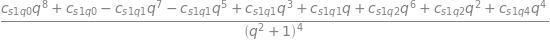

In [222]:
"""Combining m^- and m^+, first side of eq 37"""

v_tx = cos1
v_ty = sin1

side1 = (v_tx*m_minus_x + v_ty*m_minus_y)**2
side1_numer, side1_denom = side1.as_numer_denom()
side1_numer = collect(expand(side1_numer), q)
c_s1_q0, c_s1_q1, c_s1_q2, c_s1_q4 = symbols(
    "c_s1_q0, c_s1_q1, c_s1_q2, c_s1_q4")
c_s1_q0t = side1_numer.coeff(q,0)
c_s1_q1t = side1_numer.coeff(q,1)
c_s1_q2t = side1_numer.coeff(q,2)
c_s1_q4t = side1_numer.coeff(q,4)
subs = dict(zip([c_s1_q0t, c_s1_q1t, c_s1_q2t, c_s1_q4t],
                [c_s1_q0, c_s1_q1, c_s1_q2, c_s1_q4]))
side1_numer = side1_numer.subs(subs)

side1 = side1_numer/side1_denom

# side1_numer
# side1_denom
side1

In [223]:
### Get the whole left side of eq 38

m_d_plus_num, m_d_plus_den = m_d_plus.as_numer_denom()
m_d_plus_num = collect(expand(m_d_plus_num), [D,L,q])
# m_d_plus_rep = m_d_plus.

################ DO NOT REPLACE YET TO GET A LOWER ORDER POLYNOMIAL!!!!!!!!

# m_d_plus_num = m_d_plus_num.xreplace({D**2: D_2, L**2: L_2, L**4: L_4})
# m_d_plus_num = factor(m_d_plus_num, q)
# m_d_plus_num_num, m_d_plus_num_den = m_d_plus_num.as_numer_denom()
# m_d_plus_num_num = collect(expand(m_d_plus_num_num), [D,L,q])

# (c_mdp_q0,
# c_mdp_q1,
# c_mdp_q2,
# c_mdp_q3,
# c_mdp_q4,
# c_mdp_q5,
# c_mdp_q6) = symbols(
#     "c_mdp_q0, c_mdp_q1, c_mdp_q2, c_mdp_q3, c_mdp_q4, c_mdp_q5, c_mdp_q6")
# c_mdp_q0t = m_d_plus_num_num.coeff(q,0)
# c_mdp_q1t = m_d_plus_num_num.coeff(q,1)
# c_mdp_q2t = m_d_plus_num_num.coeff(q,2)
# c_mdp_q3t = m_d_plus_num_num.coeff(q,3)
# c_mdp_q4t = m_d_plus_num_num.coeff(q,4)
# c_mdp_q5t = m_d_plus_num_num.coeff(q,5)
# c_mdp_q6t = m_d_plus_num_num.coeff(q,6)
# subs = dict(zip([c_mdp_q0t, c_mdp_q1t, c_mdp_q2t, c_mdp_q3t, c_mdp_q4t, c_mdp_q5t, c_mdp_q6t],
#                 [c_mdp_q0, c_mdp_q1, c_mdp_q2, c_mdp_q3, c_mdp_q4, c_mdp_q5, c_mdp_q6]))
# m_d_plus_num_num = m_d_plus_num_num.subs(subs)


# m_d_plus_num = m_d_plus_num_num/m_d_plus_num_den


# m_d_plus_rep = m_d_plus_num/m_d_plus_den # NOW USE m_d_plus_rep INSTEAD OF M_D_PLUS

all_side1 = side1*m_d_plus
all_side1_numer, all_side1_denom = all_side1.as_numer_denom()

# all_side1_numer = all_side1_numer.xreplace({D**2: D_2, L**2: L_2, L**4: L_4})
# all_side1_numer = collect(expand(all_side1_numer), q)
# all_side1_numer_num, all_side1_numer_den = all_side1_numer.as_numer_denom()

all_side1_numer = collect(expand(all_side1_numer), [D,L,q])

all_side1 = all_side1_numer/all_side1_denom # denom L**4*(q**2 + 1)**5

# m_d_plus_rep
# m_d_plus_num
# m_d_plus_num_num
# all_side1
all_side1_numer
# all_side1_denom
# all_side1_numer_den
# all_side1_numer_num

In [224]:
"""Combining m^- and m^+, second side of eq 37"""

side2 = (v_tx*m_plus_x + v_ty*m_plus_y)**2
side2_numer, side2_denom = side2.as_numer_denom()
side2_numer = collect(expand(side2_numer), [D,L,q])

# side2_numer = side2_numer.xreplace({D**2: D_2, L**2: L_2, L**4: L_4})
# side2_numer_num, side2_numer_den = side2_numer.as_numer_denom()
# side2_numer_num = collect(expand(side2_numer_num),[D,q]) # degree 14

# # Assemble coefficients that are NOT mulitplied by D
# (c_s2_q0,
# c_s2_q1,
# c_s2_q2,
# c_s2_q3,
# c_s2_q4,
# c_s2_q5,
# c_s2_q6,
# c_s2_q7,
# c_s2_q8,
# c_s2_q9,
# c_s2_q10,
# c_s2_q11,
# c_s2_q12,
# c_s2_q13,
# c_s2_q14) = symbols(
#     "c_s2_q0, c_s2_q1, c_s2_q2, c_s2_q3, c_s2_q4, c_s2_q5, c_s2_q6, c_s2_q7, c_s2_q8, c_s2_q9, c_s2_q10, c_s2_q11, c_s2_q12, c_s2_q13, c_s2_q14")
# c_s2_q0t = side2_numer_num.coeff(q,0)
# c_s2_q1t = side2_numer_num.coeff(q,1)
# c_s2_q2t = side2_numer_num.coeff(q,2)
# c_s2_q3t = side2_numer_num.coeff(q,3)
# c_s2_q4t = side2_numer_num.coeff(q,4)
# c_s2_q5t = side2_numer_num.coeff(q,5)
# c_s2_q6t = side2_numer_num.coeff(q,6)
# c_s2_q7t = side2_numer_num.coeff(q,7)
# c_s2_q8t = side2_numer_num.coeff(q,8)
# c_s2_q9t = side2_numer_num.coeff(q,9)
# c_s2_q10t = side2_numer_num.coeff(q,10)
# c_s2_q11t = side2_numer_num.coeff(q,11)
# c_s2_q12t = side2_numer_num.coeff(q,12)
# c_s2_q13t = side2_numer_num.coeff(q,13)
# c_s2_q14t = side2_numer_num.coeff(q,14)
# subs = dict(zip([c_s2_q0t, c_s2_q1t, c_s2_q2t, c_s2_q3t, c_s2_q4t, c_s2_q5t, c_s2_q6t, c_s2_q7t, c_s2_q8t, c_s2_q9t, c_s2_q10t, c_s2_q11t, c_s2_q12t, c_s2_q13t, c_s2_q14t],
#                 [c_s2_q0, c_s2_q1, c_s2_q2, c_s2_q3, c_s2_q4, c_s2_q5, c_s2_q6, c_s2_q7, c_s2_q8, c_s2_q9, c_s2_q10, c_s2_q11, c_s2_q12, c_s2_q13, c_s2_q14]))
# side2_numer_num = side2_numer_num.subs(subs)

# # Assemble coefficients that are mulitplied by D
# D_term = collect(side2_numer_num.coeff(D,1), q)
# (c_s2_q0D,
# c_s2_q1D,
# c_s2_q2D,
# c_s2_q3D,
# c_s2_q4D,
# c_s2_q5D,
# c_s2_q6D,
# c_s2_q7D,
# c_s2_q8D,
# c_s2_q9D,
# c_s2_q10D,
# c_s2_q11D,
# c_s2_q12D,
# c_s2_q13D,
# c_s2_q14D) = symbols(
#     "c_s2_q0D, c_s2_q1D, c_s2_q2D, c_s2_q3D, c_s2_q4D, c_s2_q5D, c_s2_q6D, c_s2_q7D, c_s2_q8D, c_s2_q9D, c_s2_q10D, c_s2_q11D, c_s2_q12D, c_s2_q13D, c_s2_q14D")
# c_s2_q0Dt = D_term.coeff(q,0)
# c_s2_q1Dt = D_term.coeff(q,1)
# c_s2_q2Dt = D_term.coeff(q,2)
# c_s2_q3Dt = D_term.coeff(q,3)
# c_s2_q4Dt = D_term.coeff(q,4)
# c_s2_q5Dt = D_term.coeff(q,5)
# c_s2_q6Dt = D_term.coeff(q,6)
# c_s2_q7Dt = D_term.coeff(q,7)
# c_s2_q8Dt = D_term.coeff(q,8)
# c_s2_q9Dt = D_term.coeff(q,9)
# c_s2_q10Dt = D_term.coeff(q,10)
# c_s2_q11Dt = D_term.coeff(q,11)
# c_s2_q12Dt = D_term.coeff(q,12)
# c_s2_q13Dt = D_term.coeff(q,13)
# c_s2_q14Dt = D_term.coeff(q,14)
# subs = dict(zip([c_s2_q0Dt, c_s2_q1Dt, c_s2_q2Dt, c_s2_q3Dt, c_s2_q4Dt, c_s2_q5Dt, c_s2_q6Dt, c_s2_q7Dt, c_s2_q8Dt, c_s2_q9Dt, c_s2_q10Dt, c_s2_q11Dt, c_s2_q12Dt, c_s2_q13Dt, c_s2_q14Dt],
#                 [c_s2_q0D, c_s2_q1D, c_s2_q2D, c_s2_q3D, c_s2_q4D, c_s2_q5D, c_s2_q6D, c_s2_q7D, c_s2_q8D, c_s2_q9D, c_s2_q10D, c_s2_q11D, c_s2_q12D, c_s2_q13D, c_s2_q14D]))
# D_term = D_term.subs(subs)

# side2_numer_num = side2_numer_num - D*side2_numer_num.coeff(D,1) + D*D_term
# side2_numer = side2_numer_num/side2_numer_den


side2 = side2_numer/side2_denom # denom L**4*(q**2 + 1)**4
# side2_denom

# side2
# side2_numer
side2_denom
# side2_numer_num
# D_term
# side2_numer_den
# all_side2_numer
# m_d_minus
# all_side2_denom

In [225]:
### Get whole side 2

all_side2 = side2*m_d_minus
all_side2_numer, all_side2_denom = all_side2.as_numer_denom()

all_side2_numer = collect(expand(all_side2_numer), [D,L,q])

all_side2 = all_side2_numer/all_side2_denom # denom L**4*(q**2 + 1)**5, num order 10 (if don't count D and L replacements)

# all_side2
# all_side2_numer.coeff(D,1).coeff(q,10)
all_side2_denom

In [226]:
### Simplify denominators

all_side1_num, all_side1_den = all_side1.as_numer_denom()
all_side2_num, all_side2_den = all_side2.as_numer_denom()

# Both sides have denom L**4*(q**2 + 1)**5

all_side1_simpl = all_side1_num
all_side2_simpl = all_side2_num

all_side1_simpl
# all_side2_simpl
# all_side1_num
# all_side1_den
# all_side2_num
# all_side2_den
# all_side1 #
# all_side2 # denom L**4*(q**2 + 1)**8

In [233]:
### Combine both sides

# Assemble all that is not multiplied by D**1
all_D = all_side2_simpl.coeff(D,1) # Some of D**1 is multiplied by L**2.
side2_noD = all_side2_simpl - D*all_D
all_D = collect(all_D,[D,L,q])

all_noD = all_side1_simpl - side2_noD
all_noD = collect(expand(all_noD),[D,L,q])

# Assemble some terms in the D term
(c_aD_q0,
c_aD_q1,
c_aD_q2,
c_aD_q3,
c_aD_q4,
c_aD_q5,
c_aD_q6,
c_aD_q7,
c_aD_q8,
c_aD_q9,
c_aD_q10) = symbols(
    "c_aD_q0, c_aD_q1, c_aD_q2, c_aD_q3, c_aD_q4, c_aD_q5, c_aD_q6, c_aD_q7, c_aD_q8, c_aD_q9, c_aD_q10")
c_aD_q0t = all_D.coeff(q,0)
c_aD_q1t = all_D.coeff(q,1)
c_aD_q2t = all_D.coeff(q,2)
c_aD_q3t = all_D.coeff(q,3)
c_aD_q4t = all_D.coeff(q,4)
c_aD_q5t = all_D.coeff(q,5)
c_aD_q6t = all_D.coeff(q,6)
c_aD_q7t = all_D.coeff(q,7)
c_aD_q8t = all_D.coeff(q,8)
c_aD_q9t = all_D.coeff(q,9)
c_aD_q10t = all_D.coeff(q,10)
subs = dict(zip([c_aD_q0t, c_aD_q1t, c_aD_q2t, c_aD_q3t, c_aD_q4t, c_aD_q5t, c_aD_q6t, c_aD_q7t, c_aD_q8t, c_aD_q9t, c_aD_q10t],
                [c_aD_q0, c_aD_q1, c_aD_q2, c_aD_q3, c_aD_q4, c_aD_q5, c_aD_q6, c_aD_q7, c_aD_q8, c_aD_q9, c_aD_q10]))
all_D = all_D.subs(subs)

# Assemble the L terms in the D term
D_L_term = all_D.coeff(L,2)
D_L_term = collect(D_L_term,q)
(c_aD_q0L,
c_aD_q1L,
c_aD_q2L,
c_aD_q3L,
c_aD_q4L,
c_aD_q5L,
c_aD_q6L,
c_aD_q7L,
c_aD_q8L,
c_aD_q9L,
c_aD_q10L) = symbols(
    "c_aD_q0L, c_aD_q1L, c_aD_q2L, c_aD_q3L, c_aD_q4L, c_aD_q5L, c_aD_q6L, c_aD_q7L, c_aD_q8L, c_aD_q9L, c_aD_q10L")
c_aD_q0Lt = D_L_term.coeff(q,0)
c_aD_q1Lt = D_L_term.coeff(q,1)
c_aD_q2Lt = D_L_term.coeff(q,2)
c_aD_q3Lt = D_L_term.coeff(q,3)
c_aD_q4Lt = D_L_term.coeff(q,4)
c_aD_q5Lt = D_L_term.coeff(q,5)
c_aD_q6Lt = D_L_term.coeff(q,6)
c_aD_q7Lt = D_L_term.coeff(q,7)
c_aD_q8Lt = D_L_term.coeff(q,8)
c_aD_q9Lt = D_L_term.coeff(q,9)
c_aD_q10Lt = D_L_term.coeff(q,10)
subs = dict(zip([c_aD_q0Lt, c_aD_q1Lt, c_aD_q2Lt, c_aD_q3Lt, c_aD_q4Lt, c_aD_q5Lt, c_aD_q6Lt, c_aD_q7Lt, c_aD_q8Lt, c_aD_q9Lt, c_aD_q10Lt],
                [c_aD_q0L, c_aD_q1L, c_aD_q2L, c_aD_q3L, c_aD_q4L, c_aD_q5L, c_aD_q6L, c_aD_q7L, c_aD_q8L, c_aD_q9L, c_aD_q10L]))
D_L_term = D_L_term.subs(subs)
all_D = all_D - L**2*all_D.coeff(L,2) + L**2*D_L_term

# Assemble q terms in all_noD, anD = All terms that have No D**1
(c_anD_q0,
c_anD_q1,
c_anD_q2,
c_anD_q3,
c_anD_q4,
c_anD_q5,
c_anD_q6,
c_anD_q7,
c_anD_q8,
c_anD_q9,
c_anD_q10) = symbols(
    "c_anD_q0, c_anD_q1, c_anD_q2, c_anD_q3, c_anD_q4, c_anD_q5, c_anD_q6, c_anD_q7, c_anD_q8, c_anD_q9, c_anD_q10")
c_anD_q0t = all_noD.coeff(q,0)
c_anD_q1t = all_noD.coeff(q,1)
c_anD_q2t = all_noD.coeff(q,2)
c_anD_q3t = all_noD.coeff(q,3)
c_anD_q4t = all_noD.coeff(q,4)
c_anD_q5t = all_noD.coeff(q,5)
c_anD_q6t = all_noD.coeff(q,6)
c_anD_q7t = all_noD.coeff(q,7)
c_anD_q8t = all_noD.coeff(q,8)
c_anD_q9t = all_noD.coeff(q,9)
c_anD_q10t = all_noD.coeff(q,10)
subs = dict(zip([c_anD_q0t, c_anD_q1t, c_anD_q2t, c_anD_q3t, c_anD_q4t, c_anD_q5t, c_anD_q6t, c_anD_q7t, c_anD_q8t, c_anD_q9t, c_anD_q10t],
                [c_anD_q0, c_anD_q1, c_anD_q2, c_anD_q3, c_anD_q4, c_anD_q5, c_anD_q6, c_anD_q7, c_anD_q8, c_anD_q9, c_anD_q10]))
all_noD = all_noD.subs(subs)

# Assemble D**2 terms in all_noD
D2_all_term = collect(all_noD.coeff(D,2),q)
(c_anDD2_q0,
c_anDD2_q1,
c_anDD2_q2,
c_anDD2_q3,
c_anDD2_q4,
c_anDD2_q5,
c_anDD2_q6,
c_anDD2_q7,
c_anDD2_q8,
c_anDD2_q9,
c_anDD2_q10) = symbols(
    "c_anDD2_q0, c_anDD2_q1, c_anDD2_q2, c_anDD2_q3, c_anDD2_q4, c_anDD2_q5, c_anDD2_q6, c_anDD2_q7, c_anDD2_q8, c_anDD2_q9, c_anDD2_q10")
c_anDD2_q0t = D2_all_term.coeff(q,0)
c_anDD2_q1t = D2_all_term.coeff(q,1)
c_anDD2_q2t = D2_all_term.coeff(q,2)
c_anDD2_q3t = D2_all_term.coeff(q,3)
c_anDD2_q4t = D2_all_term.coeff(q,4)
c_anDD2_q5t = D2_all_term.coeff(q,5)
c_anDD2_q6t = D2_all_term.coeff(q,6)
c_anDD2_q7t = D2_all_term.coeff(q,7)
c_anDD2_q8t = D2_all_term.coeff(q,8)
c_anDD2_q9t = D2_all_term.coeff(q,9)
c_anDD2_q10t = D2_all_term.coeff(q,10)
subs = dict(zip([c_anDD2_q0t, c_anDD2_q1t, c_anDD2_q2t, c_anDD2_q3t, c_anDD2_q4t, c_anDD2_q5t, c_anDD2_q6t, c_anDD2_q7t, c_anDD2_q8t, c_anDD2_q9t, c_anDD2_q10t],
                [c_anDD2_q0, c_anDD2_q1, c_anDD2_q2, c_anDD2_q3, c_anDD2_q4, c_anDD2_q5, c_anDD2_q6, c_anDD2_q7, c_anDD2_q8, c_anDD2_q9, c_anDD2_q10]))
D2_all_term = D2_all_term.subs(subs)
all_noD = all_noD - D**2*all_noD.coeff(D,2) + D**2*D2_all_term

# Assemble L**2 terms in all_noD
L2_all_term = collect(all_noD.coeff(L,2),q)
(c_anDL2_q0,
c_anDL2_q1,
c_anDL2_q2,
c_anDL2_q3,
c_anDL2_q4,
c_anDL2_q5,
c_anDL2_q6,
c_anDL2_q7,
c_anDL2_q8,
c_anDL2_q9,
c_anDL2_q10) = symbols(
    "c_anDL2_q0, c_anDL2_q1, c_anDL2_q2, c_anDL2_q3, c_anDL2_q4, c_anDL2_q5, c_anDL2_q6, c_anDL2_q7, c_anDL2_q8, c_anDL2_q9, c_anDL2_q10")
c_anDL2_q0t = L2_all_term.coeff(q,0)
c_anDL2_q1t = L2_all_term.coeff(q,1)
c_anDL2_q2t = L2_all_term.coeff(q,2)
c_anDL2_q3t = L2_all_term.coeff(q,3)
c_anDL2_q4t = L2_all_term.coeff(q,4)
c_anDL2_q5t = L2_all_term.coeff(q,5)
c_anDL2_q6t = L2_all_term.coeff(q,6)
c_anDL2_q7t = L2_all_term.coeff(q,7)
c_anDL2_q8t = L2_all_term.coeff(q,8)
c_anDL2_q9t = L2_all_term.coeff(q,9)
c_anDL2_q10t = L2_all_term.coeff(q,10)
subs = dict(zip([c_anDL2_q0t, c_anDL2_q1t, c_anDL2_q2t, c_anDL2_q3t, c_anDL2_q4t, c_anDL2_q5t, c_anDL2_q6t, c_anDL2_q7t, c_anDL2_q8t, c_anDL2_q9t, c_anDL2_q10t],
                [c_anDL2_q0, c_anDL2_q1, c_anDL2_q2, c_anDL2_q3, c_anDL2_q4, c_anDL2_q5, c_anDL2_q6, c_anDL2_q7, c_anDL2_q8, c_anDL2_q9, c_anDL2_q10]))
L2_all_term = L2_all_term.subs(subs)
all_noD = all_noD - L**2*all_noD.coeff(L,2) + L**2*L2_all_term

# Assemble L**4 terms in all_noD
L4_all_term = collect(all_noD.coeff(L,4),q)
(c_anDL4_q0,
c_anDL4_q1,
c_anDL4_q2,
c_anDL4_q3,
c_anDL4_q4,
c_anDL4_q5,
c_anDL4_q6,
c_anDL4_q7,
c_anDL4_q8,
c_anDL4_q9,
c_anDL4_q10) = symbols(
    "c_anDL4_q0, c_anDL4_q1, c_anDL4_q2, c_anDL4_q3, c_anDL4_q4, c_anDL4_q5, c_anDL4_q6, c_anDL4_q7, c_anDL4_q8, c_anDL4_q9, c_anDL4_q10")
c_anDL4_q0t = L4_all_term.coeff(q,0)
c_anDL4_q1t = L4_all_term.coeff(q,1)
c_anDL4_q2t = L4_all_term.coeff(q,2)
c_anDL4_q3t = L4_all_term.coeff(q,3)
c_anDL4_q4t = L4_all_term.coeff(q,4)
c_anDL4_q5t = L4_all_term.coeff(q,5)
c_anDL4_q6t = L4_all_term.coeff(q,6)
c_anDL4_q7t = L4_all_term.coeff(q,7)
c_anDL4_q8t = L4_all_term.coeff(q,8)
c_anDL4_q9t = L4_all_term.coeff(q,9)
c_anDL4_q10t = L4_all_term.coeff(q,10)
subs = dict(zip([c_anDL4_q0t, c_anDL4_q1t, c_anDL4_q2t, c_anDL4_q3t, c_anDL4_q4t, c_anDL4_q5t, c_anDL4_q6t, c_anDL4_q7t, c_anDL4_q8t, c_anDL4_q9t, c_anDL4_q10t],
                [c_anDL4_q0, c_anDL4_q1, c_anDL4_q2, c_anDL4_q3, c_anDL4_q4, c_anDL4_q5, c_anDL4_q6, c_anDL4_q7, c_anDL4_q8, c_anDL4_q9, c_anDL4_q10]))
L4_all_term = L4_all_term.subs(subs)
all_noD = all_noD - L**4*all_noD.coeff(L,4) + L**4*L4_all_term

# side2_noD
# all_D
# D_L_term
# all_noD
# D2_all_term

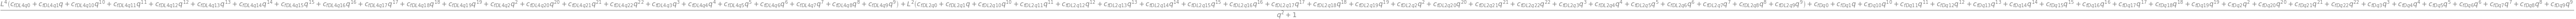

In [246]:
### Square up the D term

final_D_term_ = D**2*all_D**2 # suspected to be order 26? after substitutions
# final_D_term_ = final_D_term_.xreplace({D**2: D_2, D**4:D_4, L**2: L_2, L**4: L_4})
final_D_term_ = final_D_term_.xreplace({D**2: D_2})
final_D_term_num, final_D_term_den = final_D_term_.as_numer_denom()
final_D_term_num = collect(expand(final_D_term_num),[L,q]) # order 26

# Combine the q coefficients in final_D_term
(c_fD_q0,
c_fD_q1,
c_fD_q2,
c_fD_q3,
c_fD_q4,
c_fD_q5,
c_fD_q6,
c_fD_q7,
c_fD_q8,
c_fD_q9,
c_fD_q10,
c_fD_q11,
c_fD_q12,
c_fD_q13,
c_fD_q14,
c_fD_q15,
c_fD_q16,
c_fD_q17,
c_fD_q18,
c_fD_q19,
c_fD_q20,
c_fD_q21,
c_fD_q22) = symbols(
    "c_fD_q0, c_fD_q1, c_fD_q2, c_fD_q3, c_fD_q4, c_fD_q5, c_fD_q6, c_fD_q7, c_fD_q8, c_fD_q9, c_fD_q10, c_fD_q11, c_fD_q12, c_fD_q13, c_fD_q14, c_fD_q15, c_fD_q16, c_fD_q17, c_fD_q18, c_fD_q19, c_fD_q20, c_fD_q21, c_fD_q22")
c_fD_q0t = final_D_term_num.coeff(q,0)
c_fD_q1t = final_D_term_num.coeff(q,1)
c_fD_q2t = final_D_term_num.coeff(q,2)
c_fD_q3t = final_D_term_num.coeff(q,3)
c_fD_q4t = final_D_term_num.coeff(q,4)
c_fD_q5t = final_D_term_num.coeff(q,5)
c_fD_q6t = final_D_term_num.coeff(q,6)
c_fD_q7t = final_D_term_num.coeff(q,7)
c_fD_q8t = final_D_term_num.coeff(q,8)
c_fD_q9t = final_D_term_num.coeff(q,9)
c_fD_q10t = final_D_term_num.coeff(q,10)
c_fD_q11t = final_D_term_num.coeff(q,11)
c_fD_q12t = final_D_term_num.coeff(q,12)
c_fD_q13t = final_D_term_num.coeff(q,13)
c_fD_q14t = final_D_term_num.coeff(q,14)
c_fD_q15t = final_D_term_num.coeff(q,15)
c_fD_q16t = final_D_term_num.coeff(q,16)
c_fD_q17t = final_D_term_num.coeff(q,17)
c_fD_q18t = final_D_term_num.coeff(q,18)
c_fD_q19t = final_D_term_num.coeff(q,19)
c_fD_q20t = final_D_term_num.coeff(q,20)
c_fD_q21t = final_D_term_num.coeff(q,21)
c_fD_q22t = final_D_term_num.coeff(q,22)
subs = dict(zip([c_fD_q0t, c_fD_q1t, c_fD_q2t, c_fD_q3t, c_fD_q4t, c_fD_q5t, c_fD_q6t, c_fD_q7t, c_fD_q8t, c_fD_q9t, c_fD_q10t, c_fD_q11t, c_fD_q12t, c_fD_q13t, c_fD_q14t, c_fD_q15t, c_fD_q16t, c_fD_q17t, c_fD_q18t, c_fD_q19t, c_fD_q20t, c_fD_q21t, c_fD_q22t],
                [c_fD_q0, c_fD_q1, c_fD_q2, c_fD_q3, c_fD_q4, c_fD_q5, c_fD_q6, c_fD_q7, c_fD_q8, c_fD_q9, c_fD_q10, c_fD_q11, c_fD_q12, c_fD_q13, c_fD_q14, c_fD_q15, c_fD_q16, c_fD_q17, c_fD_q18, c_fD_q19, c_fD_q20, c_fD_q21, c_fD_q22]))
final_D_term_num = final_D_term_num.subs(subs)

# Combine the L**2 coefficients in final_D_term
L_2_coeff = collect(final_D_term_num.coeff(L,2), q)
(c_fDL2_q0,
c_fDL2_q1,
c_fDL2_q2,
c_fDL2_q3,
c_fDL2_q4,
c_fDL2_q5,
c_fDL2_q6,
c_fDL2_q7,
c_fDL2_q8,
c_fDL2_q9,
c_fDL2_q10,
c_fDL2_q11,
c_fDL2_q12,
c_fDL2_q13,
c_fDL2_q14,
c_fDL2_q15,
c_fDL2_q16,
c_fDL2_q17,
c_fDL2_q18,
c_fDL2_q19,
c_fDL2_q20,
c_fDL2_q21,
c_fDL2_q22) = symbols(
    "c_fDL2_q0, c_fDL2_q1, c_fDL2_q2, c_fDL2_q3, c_fDL2_q4, c_fDL2_q5, c_fDL2_q6, c_fDL2_q7, c_fDL2_q8, c_fDL2_q9, c_fDL2_q10, c_fDL2_q11, c_fDL2_q12, c_fDL2_q13, c_fDL2_q14, c_fDL2_q15, c_fDL2_q16, c_fDL2_q17, c_fDL2_q18, c_fDL2_q19, c_fDL2_q20, c_fDL2_q21, c_fDL2_q22")
c_fDL2_q0t = L_2_coeff.coeff(q,0)
c_fDL2_q1t = L_2_coeff.coeff(q,1)
c_fDL2_q2t = L_2_coeff.coeff(q,2)
c_fDL2_q3t = L_2_coeff.coeff(q,3)
c_fDL2_q4t = L_2_coeff.coeff(q,4)
c_fDL2_q5t = L_2_coeff.coeff(q,5)
c_fDL2_q6t = L_2_coeff.coeff(q,6)
c_fDL2_q7t = L_2_coeff.coeff(q,7)
c_fDL2_q8t = L_2_coeff.coeff(q,8)
c_fDL2_q9t = L_2_coeff.coeff(q,9)
c_fDL2_q10t = L_2_coeff.coeff(q,10)
c_fDL2_q11t = L_2_coeff.coeff(q,11)
c_fDL2_q12t = L_2_coeff.coeff(q,12)
c_fDL2_q13t = L_2_coeff.coeff(q,13)
c_fDL2_q14t = L_2_coeff.coeff(q,14)
c_fDL2_q15t = L_2_coeff.coeff(q,15)
c_fDL2_q16t = L_2_coeff.coeff(q,16)
c_fDL2_q17t = L_2_coeff.coeff(q,17)
c_fDL2_q18t = L_2_coeff.coeff(q,18)
c_fDL2_q19t = L_2_coeff.coeff(q,19)
c_fDL2_q20t = L_2_coeff.coeff(q,20)
c_fDL2_q21t = L_2_coeff.coeff(q,21)
c_fDL2_q22t = L_2_coeff.coeff(q,22)
subs = dict(zip([c_fDL2_q0t, c_fDL2_q1t, c_fDL2_q2t, c_fDL2_q3t, c_fDL2_q4t, c_fDL2_q5t, c_fDL2_q6t, c_fDL2_q7t, c_fDL2_q8t, c_fDL2_q9t, c_fDL2_q10t, c_fDL2_q11t, c_fDL2_q12t, c_fDL2_q13t, c_fDL2_q14t, c_fDL2_q15t, c_fDL2_q16t, c_fDL2_q17t, c_fDL2_q18t, c_fDL2_q19t, c_fDL2_q20t, c_fDL2_q21t, c_fDL2_q22t],
                [c_fDL2_q0, c_fDL2_q1, c_fDL2_q2, c_fDL2_q3, c_fDL2_q4, c_fDL2_q5, c_fDL2_q6, c_fDL2_q7, c_fDL2_q8, c_fDL2_q9, c_fDL2_q10, c_fDL2_q11, c_fDL2_q12, c_fDL2_q13, c_fDL2_q14, c_fDL2_q15, c_fDL2_q16, c_fDL2_q17, c_fDL2_q18, c_fDL2_q19, c_fDL2_q20, c_fDL2_q21, c_fDL2_q22]))
L_2_coeff = L_2_coeff.subs(subs)
final_D_term_num = final_D_term_num - L**2*final_D_term_num.coeff(L,2) + L**2*L_2_coeff

# Combine the L**4 coefficients in final_D_term
L_4_coeff = collect(final_D_term_num.coeff(L,4), q)
(c_fDL4_q0,
c_fDL4_q1,
c_fDL4_q2,
c_fDL4_q3,
c_fDL4_q4,
c_fDL4_q5,
c_fDL4_q6,
c_fDL4_q7,
c_fDL4_q8,
c_fDL4_q9,
c_fDL4_q10,
c_fDL4_q11,
c_fDL4_q12,
c_fDL4_q13,
c_fDL4_q14,
c_fDL4_q15,
c_fDL4_q16,
c_fDL4_q17,
c_fDL4_q18,
c_fDL4_q19,
c_fDL4_q20,
c_fDL4_q21,
c_fDL4_q22) = symbols(
    "c_fDL4_q0, c_fDL4_q1, c_fDL4_q2, c_fDL4_q3, c_fDL4_q4, c_fDL4_q5, c_fDL4_q6, c_fDL4_q7, c_fDL4_q8, c_fDL4_q9, c_fDL4_q10, c_fDL4_q11, c_fDL4_q12, c_fDL4_q13, c_fDL4_q14, c_fDL4_q15, c_fDL4_q16, c_fDL4_q17, c_fDL4_q18, c_fDL4_q19, c_fDL4_q20, c_fDL4_q21, c_fDL4_q22")
c_fDL4_q0t = L_4_coeff.coeff(q,0)
c_fDL4_q1t = L_4_coeff.coeff(q,1)
c_fDL4_q2t = L_4_coeff.coeff(q,2)
c_fDL4_q3t = L_4_coeff.coeff(q,3)
c_fDL4_q4t = L_4_coeff.coeff(q,4)
c_fDL4_q5t = L_4_coeff.coeff(q,5)
c_fDL4_q6t = L_4_coeff.coeff(q,6)
c_fDL4_q7t = L_4_coeff.coeff(q,7)
c_fDL4_q8t = L_4_coeff.coeff(q,8)
c_fDL4_q9t = L_4_coeff.coeff(q,9)
c_fDL4_q10t = L_4_coeff.coeff(q,10)
c_fDL4_q11t = L_4_coeff.coeff(q,11)
c_fDL4_q12t = L_4_coeff.coeff(q,12)
c_fDL4_q13t = L_4_coeff.coeff(q,13)
c_fDL4_q14t = L_4_coeff.coeff(q,14)
c_fDL4_q15t = L_4_coeff.coeff(q,15)
c_fDL4_q16t = L_4_coeff.coeff(q,16)
c_fDL4_q17t = L_4_coeff.coeff(q,17)
c_fDL4_q18t = L_4_coeff.coeff(q,18)
c_fDL4_q19t = L_4_coeff.coeff(q,19)
c_fDL4_q20t = L_4_coeff.coeff(q,20)
c_fDL4_q21t = L_4_coeff.coeff(q,21)
c_fDL4_q22t = L_4_coeff.coeff(q,22)
subs = dict(zip([c_fDL4_q0t, c_fDL4_q1t, c_fDL4_q2t, c_fDL4_q3t, c_fDL4_q4t, c_fDL4_q5t, c_fDL4_q6t, c_fDL4_q7t, c_fDL4_q8t, c_fDL4_q9t, c_fDL4_q10t, c_fDL4_q11t, c_fDL4_q12t, c_fDL4_q13t, c_fDL4_q14t, c_fDL4_q15t, c_fDL4_q16t, c_fDL4_q17t, c_fDL4_q18t, c_fDL4_q19t, c_fDL4_q20t, c_fDL4_q21t, c_fDL4_q22t],
                [c_fDL4_q0, c_fDL4_q1, c_fDL4_q2, c_fDL4_q3, c_fDL4_q4, c_fDL4_q5, c_fDL4_q6, c_fDL4_q7, c_fDL4_q8, c_fDL4_q9, c_fDL4_q10, c_fDL4_q11, c_fDL4_q12, c_fDL4_q13, c_fDL4_q14, c_fDL4_q15, c_fDL4_q16, c_fDL4_q17, c_fDL4_q18, c_fDL4_q19, c_fDL4_q20, c_fDL4_q21, c_fDL4_q22]))
L_4_coeff = L_4_coeff.subs(subs)
final_D_term_num = final_D_term_num - L**4*final_D_term_num.coeff(L,4) + L**4*L_4_coeff

final_D_term_wD2 = final_D_term_num/final_D_term_den

# final_D_term_num # Order 22 after replacing D**2
# final_D_term_den # (q**2+1) after replacing D**2
final_D_term_wD2



In [263]:
### Replace L**2 and L**4 in the final D term

final_D_term = final_D_term_wD2.xreplace({L**2: L_2, L**4: L_4})
final_D_term_num_, final_D_term_den_ = final_D_term.as_numer_denom()
final_D_term_num_ = collect(expand(final_D_term_num_),q) # order 28

final_D_term = final_D_term_num_/final_D_term_den_

# final_D_term_num_
# final_D_term_den_
final_D_term

In [190]:
### Square up the no D term

all_noD_2 = all_noD**2
all_noD_2 = collect(expand(all_noD_2),[D,L,q])

all_noD_2

In [264]:
### Replace the D**2 and D**4 in the noD term

all_noD_2_subD = all_noD_2.xreplace({D**2: D_2, D**4: D_4})
all_noD_2_subD_num, all_noD_2_subD_den = all_noD_2_subD.as_numer_denom()
all_noD_2_subD_num = collect(expand(all_noD_2_subD_num),[L,q])

all_noD_2_subD = all_noD_2_subD_num/all_noD_2_subD_den

# Assemble q coefficients
(c_fnD_q0,
c_fnD_q1,
c_fnD_q2,
c_fnD_q3,
c_fnD_q4,
c_fnD_q5,
c_fnD_q6,
c_fnD_q7,
c_fnD_q8,
c_fnD_q9,
c_fnD_q10,
c_fnD_q11,
c_fnD_q12,
c_fnD_q13,
c_fnD_q14,
c_fnD_q15,
c_fnD_q16,
c_fnD_q17,
c_fnD_q18,
c_fnD_q19,
c_fnD_q20,
c_fnD_q21,
c_fnD_q22,
c_fnD_q23,
c_fnD_q24,
c_fnD_q25,
c_fnD_q26) = symbols(
    "c_fnD_q0, c_fnD_q1, c_fnD_q2, c_fnD_q3, c_fnD_q4, c_fnD_q5, c_fnD_q6, c_fnD_q7, c_fnD_q8, c_fnD_q9, c_fnD_q10, c_fnD_q11, c_fnD_q12, c_fnD_q13, c_fnD_q14, c_fnD_q15, c_fnD_q16, c_fnD_q17, c_fnD_q18, c_fnD_q19, c_fnD_q20, c_fnD_q21, c_fnD_q22, c_fnD_q23, c_fnD_q24, c_fnD_q25, c_fnD_q26")
c_fnD_q0t = all_noD_2_subD_num.coeff(q,0)
c_fnD_q1t = all_noD_2_subD_num.coeff(q,1)
c_fnD_q2t = all_noD_2_subD_num.coeff(q,2)
c_fnD_q3t = all_noD_2_subD_num.coeff(q,3)
c_fnD_q4t = all_noD_2_subD_num.coeff(q,4)
c_fnD_q5t = all_noD_2_subD_num.coeff(q,5)
c_fnD_q6t = all_noD_2_subD_num.coeff(q,6)
c_fnD_q7t = all_noD_2_subD_num.coeff(q,7)
c_fnD_q8t = all_noD_2_subD_num.coeff(q,8)
c_fnD_q9t = all_noD_2_subD_num.coeff(q,9)
c_fnD_q10t = all_noD_2_subD_num.coeff(q,10)
c_fnD_q11t = all_noD_2_subD_num.coeff(q,11)
c_fnD_q12t = all_noD_2_subD_num.coeff(q,12)
c_fnD_q13t = all_noD_2_subD_num.coeff(q,13)
c_fnD_q14t = all_noD_2_subD_num.coeff(q,14)
c_fnD_q15t = all_noD_2_subD_num.coeff(q,15)
c_fnD_q16t = all_noD_2_subD_num.coeff(q,16)
c_fnD_q17t = all_noD_2_subD_num.coeff(q,17)
c_fnD_q18t = all_noD_2_subD_num.coeff(q,18)
c_fnD_q19t = all_noD_2_subD_num.coeff(q,19)
c_fnD_q20t = all_noD_2_subD_num.coeff(q,20)
c_fnD_q21t = all_noD_2_subD_num.coeff(q,21)
c_fnD_q22t = all_noD_2_subD_num.coeff(q,22)
c_fnD_q23t = all_noD_2_subD_num.coeff(q,23)
c_fnD_q24t = all_noD_2_subD_num.coeff(q,24)
c_fnD_q25t = all_noD_2_subD_num.coeff(q,25)
c_fnD_q26t = all_noD_2_subD_num.coeff(q,26)
subs = dict(zip([c_fnD_q0t, c_fnD_q1t, c_fnD_q2t, c_fnD_q3t, c_fnD_q4t, c_fnD_q5t, c_fnD_q6t, c_fnD_q7t, c_fnD_q8t, c_fnD_q9t, c_fnD_q10t, c_fnD_q11t, c_fnD_q12t, c_fnD_q13t, c_fnD_q14t, c_fnD_q15t, c_fnD_q16t, c_fnD_q17t, c_fnD_q18t, c_fnD_q19t, c_fnD_q20t, c_fnD_q21t, c_fnD_q22t, c_fnD_q23t, c_fnD_q24t, c_fnD_q25t, c_fnD_q26t],
                [c_fnD_q0, c_fnD_q1, c_fnD_q2, c_fnD_q3, c_fnD_q4, c_fnD_q5, c_fnD_q6, c_fnD_q7, c_fnD_q8, c_fnD_q9, c_fnD_q10, c_fnD_q11, c_fnD_q12, c_fnD_q13, c_fnD_q14, c_fnD_q15, c_fnD_q16, c_fnD_q17, c_fnD_q18, c_fnD_q19, c_fnD_q20, c_fnD_q21, c_fnD_q22, c_fnD_q23, c_fnD_q24, c_fnD_q25, c_fnD_q26]))
all_noD_2_subD_num = all_noD_2_subD_num.subs(subs)

# Assemble L**2 coefficients
L2_coeff = collect(all_noD_2_subD_num.coeff(L,2), q)
(c_fnDL2_q0,
c_fnDL2_q1,
c_fnDL2_q2,
c_fnDL2_q3,
c_fnDL2_q4,
c_fnDL2_q5,
c_fnDL2_q6,
c_fnDL2_q7,
c_fnDL2_q8,
c_fnDL2_q9,
c_fnDL2_q10,
c_fnDL2_q11,
c_fnDL2_q12,
c_fnDL2_q13,
c_fnDL2_q14,
c_fnDL2_q15,
c_fnDL2_q16,
c_fnDL2_q17,
c_fnDL2_q18,
c_fnDL2_q19,
c_fnDL2_q20,
c_fnDL2_q21,
c_fnDL2_q22,
c_fnDL2_q23,
c_fnDL2_q24,
c_fnDL2_q25,
c_fnDL2_q26) = symbols(
    "c_fnDL2_q0, c_fnDL2_q1, c_fnDL2_q2, c_fnDL2_q3, c_fnDL2_q4, c_fnDL2_q5, c_fnDL2_q6, c_fnDL2_q7, c_fnDL2_q8, c_fnDL2_q9, c_fnDL2_q10, c_fnDL2_q11, c_fnDL2_q12, c_fnDL2_q13, c_fnDL2_q14, c_fnDL2_q15, c_fnDL2_q16, c_fnDL2_q17, c_fnDL2_q18, c_fnDL2_q19, c_fnDL2_q20, c_fnDL2_q21, c_fnDL2_q22, c_fnDL2_q23, c_fnDL2_q24, c_fnDL2_q25, c_fnDL2_q26")
c_fnDL2_q0t = L2_coeff.coeff(q,0)
c_fnDL2_q1t = L2_coeff.coeff(q,1)
c_fnDL2_q2t = L2_coeff.coeff(q,2)
c_fnDL2_q3t = L2_coeff.coeff(q,3)
c_fnDL2_q4t = L2_coeff.coeff(q,4)
c_fnDL2_q5t = L2_coeff.coeff(q,5)
c_fnDL2_q6t = L2_coeff.coeff(q,6)
c_fnDL2_q7t = L2_coeff.coeff(q,7)
c_fnDL2_q8t = L2_coeff.coeff(q,8)
c_fnDL2_q9t = L2_coeff.coeff(q,9)
c_fnDL2_q10t = L2_coeff.coeff(q,10)
c_fnDL2_q11t = L2_coeff.coeff(q,11)
c_fnDL2_q12t = L2_coeff.coeff(q,12)
c_fnDL2_q13t = L2_coeff.coeff(q,13)
c_fnDL2_q14t = L2_coeff.coeff(q,14)
c_fnDL2_q15t = L2_coeff.coeff(q,15)
c_fnDL2_q16t = L2_coeff.coeff(q,16)
c_fnDL2_q17t = L2_coeff.coeff(q,17)
c_fnDL2_q18t = L2_coeff.coeff(q,18)
c_fnDL2_q19t = L2_coeff.coeff(q,19)
c_fnDL2_q20t = L2_coeff.coeff(q,20)
c_fnDL2_q21t = L2_coeff.coeff(q,21)
c_fnDL2_q22t = L2_coeff.coeff(q,22)
c_fnDL2_q23t = L2_coeff.coeff(q,23)
c_fnDL2_q24t = L2_coeff.coeff(q,24)
c_fnDL2_q25t = L2_coeff.coeff(q,25)
c_fnDL2_q26t = L2_coeff.coeff(q,26)
subs = dict(zip([c_fnDL2_q0t, c_fnDL2_q1t, c_fnDL2_q2t, c_fnDL2_q3t, c_fnDL2_q4t, c_fnDL2_q5t, c_fnDL2_q6t, c_fnDL2_q7t, c_fnDL2_q8t, c_fnDL2_q9t, c_fnDL2_q10t, c_fnDL2_q11t, c_fnDL2_q12t, c_fnDL2_q13t, c_fnDL2_q14t, c_fnDL2_q15t, c_fnDL2_q16t, c_fnDL2_q17t, c_fnDL2_q18t, c_fnDL2_q19t, c_fnDL2_q20t, c_fnDL2_q21t, c_fnDL2_q22t, c_fnDL2_q23t, c_fnDL2_q24t, c_fnDL2_q25t, c_fnDL2_q26t],
                [c_fnDL2_q0, c_fnDL2_q1, c_fnDL2_q2, c_fnDL2_q3, c_fnDL2_q4, c_fnDL2_q5, c_fnDL2_q6, c_fnDL2_q7, c_fnDL2_q8, c_fnDL2_q9, c_fnDL2_q10, c_fnDL2_q11, c_fnDL2_q12, c_fnDL2_q13, c_fnDL2_q14, c_fnDL2_q15, c_fnDL2_q16, c_fnDL2_q17, c_fnDL2_q18, c_fnDL2_q19, c_fnDL2_q20, c_fnDL2_q21, c_fnDL2_q22, c_fnDL2_q23, c_fnDL2_q24, c_fnDL2_q25, c_fnDL2_q26]))
L2_coeff = L2_coeff.subs(subs)
all_noD_2_subD_num = all_noD_2_subD_num - L**2*all_noD_2_subD_num.coeff(L,2) + L**2*L2_coeff

# Assemble L**4 coefficients
L4_coeff = collect(all_noD_2_subD_num.coeff(L,4), q)
(c_fnDL4_q0,
c_fnDL4_q1,
c_fnDL4_q2,
c_fnDL4_q3,
c_fnDL4_q4,
c_fnDL4_q5,
c_fnDL4_q6,
c_fnDL4_q7,
c_fnDL4_q8,
c_fnDL4_q9,
c_fnDL4_q10,
c_fnDL4_q11,
c_fnDL4_q12,
c_fnDL4_q13,
c_fnDL4_q14,
c_fnDL4_q15,
c_fnDL4_q16,
c_fnDL4_q17,
c_fnDL4_q18,
c_fnDL4_q19,
c_fnDL4_q20,
c_fnDL4_q21,
c_fnDL4_q22,
c_fnDL4_q23,
c_fnDL4_q24,
c_fnDL4_q25,
c_fnDL4_q26) = symbols(
    "c_fnDL4_q0, c_fnDL4_q1, c_fnDL4_q2, c_fnDL4_q3, c_fnDL4_q4, c_fnDL4_q5, c_fnDL4_q6, c_fnDL4_q7, c_fnDL4_q8, c_fnDL4_q9, c_fnDL4_q10, c_fnDL4_q11, c_fnDL4_q12, c_fnDL4_q13, c_fnDL4_q14, c_fnDL4_q15, c_fnDL4_q16, c_fnDL4_q17, c_fnDL4_q18, c_fnDL4_q19, c_fnDL4_q20, c_fnDL4_q21, c_fnDL4_q22, c_fnDL4_q23, c_fnDL4_q24, c_fnDL4_q25, c_fnDL4_q26")
c_fnDL4_q0t = L4_coeff.coeff(q,0)
c_fnDL4_q1t = L4_coeff.coeff(q,1)
c_fnDL4_q2t = L4_coeff.coeff(q,2)
c_fnDL4_q3t = L4_coeff.coeff(q,3)
c_fnDL4_q4t = L4_coeff.coeff(q,4)
c_fnDL4_q5t = L4_coeff.coeff(q,5)
c_fnDL4_q6t = L4_coeff.coeff(q,6)
c_fnDL4_q7t = L4_coeff.coeff(q,7)
c_fnDL4_q8t = L4_coeff.coeff(q,8)
c_fnDL4_q9t = L4_coeff.coeff(q,9)
c_fnDL4_q10t = L4_coeff.coeff(q,10)
c_fnDL4_q11t = L4_coeff.coeff(q,11)
c_fnDL4_q12t = L4_coeff.coeff(q,12)
c_fnDL4_q13t = L4_coeff.coeff(q,13)
c_fnDL4_q14t = L4_coeff.coeff(q,14)
c_fnDL4_q15t = L4_coeff.coeff(q,15)
c_fnDL4_q16t = L4_coeff.coeff(q,16)
c_fnDL4_q17t = L4_coeff.coeff(q,17)
c_fnDL4_q18t = L4_coeff.coeff(q,18)
c_fnDL4_q19t = L4_coeff.coeff(q,19)
c_fnDL4_q20t = L4_coeff.coeff(q,20)
c_fnDL4_q21t = L4_coeff.coeff(q,21)
c_fnDL4_q22t = L4_coeff.coeff(q,22)
c_fnDL4_q23t = L4_coeff.coeff(q,23)
c_fnDL4_q24t = L4_coeff.coeff(q,24)
c_fnDL4_q25t = L4_coeff.coeff(q,25)
c_fnDL4_q26t = L4_coeff.coeff(q,26)
subs = dict(zip([c_fnDL4_q0t, c_fnDL4_q1t, c_fnDL4_q2t, c_fnDL4_q3t, c_fnDL4_q4t, c_fnDL4_q5t, c_fnDL4_q6t, c_fnDL4_q7t, c_fnDL4_q8t, c_fnDL4_q9t, c_fnDL4_q10t, c_fnDL4_q11t, c_fnDL4_q12t, c_fnDL4_q13t, c_fnDL4_q14t, c_fnDL4_q15t, c_fnDL4_q16t, c_fnDL4_q17t, c_fnDL4_q18t, c_fnDL4_q19t, c_fnDL4_q20t, c_fnDL4_q21t, c_fnDL4_q22t, c_fnDL4_q23t, c_fnDL4_q24t, c_fnDL4_q25t, c_fnDL4_q26t],
                [c_fnDL4_q0, c_fnDL4_q1, c_fnDL4_q2, c_fnDL4_q3, c_fnDL4_q4, c_fnDL4_q5, c_fnDL4_q6, c_fnDL4_q7, c_fnDL4_q8, c_fnDL4_q9, c_fnDL4_q10, c_fnDL4_q11, c_fnDL4_q12, c_fnDL4_q13, c_fnDL4_q14, c_fnDL4_q15, c_fnDL4_q16, c_fnDL4_q17, c_fnDL4_q18, c_fnDL4_q19, c_fnDL4_q20, c_fnDL4_q21, c_fnDL4_q22, c_fnDL4_q23, c_fnDL4_q24, c_fnDL4_q25, c_fnDL4_q26]))
L4_coeff = L4_coeff.subs(subs)
all_noD_2_subD_num = all_noD_2_subD_num - L**4*all_noD_2_subD_num.coeff(L,4) + L**4*L4_coeff

# Assemble L**6 coefficients
L6_coeff = collect(all_noD_2_subD_num.coeff(L,6), q)
(c_fnDL6_q0,
c_fnDL6_q1,
c_fnDL6_q2,
c_fnDL6_q3,
c_fnDL6_q4,
c_fnDL6_q5,
c_fnDL6_q6,
c_fnDL6_q7,
c_fnDL6_q8,
c_fnDL6_q9,
c_fnDL6_q10,
c_fnDL6_q11,
c_fnDL6_q12,
c_fnDL6_q13,
c_fnDL6_q14,
c_fnDL6_q15,
c_fnDL6_q16,
c_fnDL6_q17,
c_fnDL6_q18,
c_fnDL6_q19,
c_fnDL6_q20,
c_fnDL6_q21,
c_fnDL6_q22,
c_fnDL6_q23,
c_fnDL6_q24,
c_fnDL6_q25,
c_fnDL6_q26) = symbols(
    "c_fnDL6_q0, c_fnDL6_q1, c_fnDL6_q2, c_fnDL6_q3, c_fnDL6_q4, c_fnDL6_q5, c_fnDL6_q6, c_fnDL6_q7, c_fnDL6_q8, c_fnDL6_q9, c_fnDL6_q10, c_fnDL6_q11, c_fnDL6_q12, c_fnDL6_q13, c_fnDL6_q14, c_fnDL6_q15, c_fnDL6_q16, c_fnDL6_q17, c_fnDL6_q18, c_fnDL6_q19, c_fnDL6_q20, c_fnDL6_q21, c_fnDL6_q22, c_fnDL6_q23, c_fnDL6_q24, c_fnDL6_q25, c_fnDL6_q26")
c_fnDL6_q0t = L6_coeff.coeff(q,0)
c_fnDL6_q1t = L6_coeff.coeff(q,1)
c_fnDL6_q2t = L6_coeff.coeff(q,2)
c_fnDL6_q3t = L6_coeff.coeff(q,3)
c_fnDL6_q4t = L6_coeff.coeff(q,4)
c_fnDL6_q5t = L6_coeff.coeff(q,5)
c_fnDL6_q6t = L6_coeff.coeff(q,6)
c_fnDL6_q7t = L6_coeff.coeff(q,7)
c_fnDL6_q8t = L6_coeff.coeff(q,8)
c_fnDL6_q9t = L6_coeff.coeff(q,9)
c_fnDL6_q10t = L6_coeff.coeff(q,10)
c_fnDL6_q11t = L6_coeff.coeff(q,11)
c_fnDL6_q12t = L6_coeff.coeff(q,12)
c_fnDL6_q13t = L6_coeff.coeff(q,13)
c_fnDL6_q14t = L6_coeff.coeff(q,14)
c_fnDL6_q15t = L6_coeff.coeff(q,15)
c_fnDL6_q16t = L6_coeff.coeff(q,16)
c_fnDL6_q17t = L6_coeff.coeff(q,17)
c_fnDL6_q18t = L6_coeff.coeff(q,18)
c_fnDL6_q19t = L6_coeff.coeff(q,19)
c_fnDL6_q20t = L6_coeff.coeff(q,20)
c_fnDL6_q21t = L6_coeff.coeff(q,21)
c_fnDL6_q22t = L6_coeff.coeff(q,22)
c_fnDL6_q23t = L6_coeff.coeff(q,23)
c_fnDL6_q24t = L6_coeff.coeff(q,24)
c_fnDL6_q25t = L6_coeff.coeff(q,25)
c_fnDL6_q26t = L6_coeff.coeff(q,26)
subs = dict(zip([c_fnDL6_q0t, c_fnDL6_q1t, c_fnDL6_q2t, c_fnDL6_q3t, c_fnDL6_q4t, c_fnDL6_q5t, c_fnDL6_q6t, c_fnDL6_q7t, c_fnDL6_q8t, c_fnDL6_q9t, c_fnDL6_q10t, c_fnDL6_q11t, c_fnDL6_q12t, c_fnDL6_q13t, c_fnDL6_q14t, c_fnDL6_q15t, c_fnDL6_q16t, c_fnDL6_q17t, c_fnDL6_q18t, c_fnDL6_q19t, c_fnDL6_q20t, c_fnDL6_q21t, c_fnDL6_q22t, c_fnDL6_q23t, c_fnDL6_q24t, c_fnDL6_q25t, c_fnDL6_q26t],
                [c_fnDL6_q0, c_fnDL6_q1, c_fnDL6_q2, c_fnDL6_q3, c_fnDL6_q4, c_fnDL6_q5, c_fnDL6_q6, c_fnDL6_q7, c_fnDL6_q8, c_fnDL6_q9, c_fnDL6_q10, c_fnDL6_q11, c_fnDL6_q12, c_fnDL6_q13, c_fnDL6_q14, c_fnDL6_q15, c_fnDL6_q16, c_fnDL6_q17, c_fnDL6_q18, c_fnDL6_q19, c_fnDL6_q20, c_fnDL6_q21, c_fnDL6_q22, c_fnDL6_q23, c_fnDL6_q24, c_fnDL6_q25, c_fnDL6_q26]))
L6_coeff = L6_coeff.subs(subs)
all_noD_2_subD_num = all_noD_2_subD_num - L**6*all_noD_2_subD_num.coeff(L,6) + L**6*L6_coeff

# Assemble L**8 coefficients
L8_coeff = collect(all_noD_2_subD_num.coeff(L,8), q)
(c_fnDL8_q0,
c_fnDL8_q1,
c_fnDL8_q2,
c_fnDL8_q3,
c_fnDL8_q4,
c_fnDL8_q5,
c_fnDL8_q6,
c_fnDL8_q7,
c_fnDL8_q8,
c_fnDL8_q9,
c_fnDL8_q10,
c_fnDL8_q11,
c_fnDL8_q12,
c_fnDL8_q13,
c_fnDL8_q14,
c_fnDL8_q15,
c_fnDL8_q16,
c_fnDL8_q17,
c_fnDL8_q18,
c_fnDL8_q19,
c_fnDL8_q20,
c_fnDL8_q21,
c_fnDL8_q22,
c_fnDL8_q23,
c_fnDL8_q24,
c_fnDL8_q25,
c_fnDL8_q26) = symbols(
    "c_fnDL8_q0, c_fnDL8_q1, c_fnDL8_q2, c_fnDL8_q3, c_fnDL8_q4, c_fnDL8_q5, c_fnDL8_q6, c_fnDL8_q7, c_fnDL8_q8, c_fnDL8_q9, c_fnDL8_q10, c_fnDL8_q11, c_fnDL8_q12, c_fnDL8_q13, c_fnDL8_q14, c_fnDL8_q15, c_fnDL8_q16, c_fnDL8_q17, c_fnDL8_q18, c_fnDL8_q19, c_fnDL8_q20, c_fnDL8_q21, c_fnDL8_q22, c_fnDL8_q23, c_fnDL8_q24, c_fnDL8_q25, c_fnDL8_q26")
c_fnDL8_q0t = L8_coeff.coeff(q,0)
c_fnDL8_q1t = L8_coeff.coeff(q,1)
c_fnDL8_q2t = L8_coeff.coeff(q,2)
c_fnDL8_q3t = L8_coeff.coeff(q,3)
c_fnDL8_q4t = L8_coeff.coeff(q,4)
c_fnDL8_q5t = L8_coeff.coeff(q,5)
c_fnDL8_q6t = L8_coeff.coeff(q,6)
c_fnDL8_q7t = L8_coeff.coeff(q,7)
c_fnDL8_q8t = L8_coeff.coeff(q,8)
c_fnDL8_q9t = L8_coeff.coeff(q,9)
c_fnDL8_q10t = L8_coeff.coeff(q,10)
c_fnDL8_q11t = L8_coeff.coeff(q,11)
c_fnDL8_q12t = L8_coeff.coeff(q,12)
c_fnDL8_q13t = L8_coeff.coeff(q,13)
c_fnDL8_q14t = L8_coeff.coeff(q,14)
c_fnDL8_q15t = L8_coeff.coeff(q,15)
c_fnDL8_q16t = L8_coeff.coeff(q,16)
c_fnDL8_q17t = L8_coeff.coeff(q,17)
c_fnDL8_q18t = L8_coeff.coeff(q,18)
c_fnDL8_q19t = L8_coeff.coeff(q,19)
c_fnDL8_q20t = L8_coeff.coeff(q,20)
c_fnDL8_q21t = L8_coeff.coeff(q,21)
c_fnDL8_q22t = L8_coeff.coeff(q,22)
c_fnDL8_q23t = L8_coeff.coeff(q,23)
c_fnDL8_q24t = L8_coeff.coeff(q,24)
c_fnDL8_q25t = L8_coeff.coeff(q,25)
c_fnDL8_q26t = L6_coeff.coeff(q,26)
subs = dict(zip([c_fnDL8_q0t, c_fnDL8_q1t, c_fnDL8_q2t, c_fnDL8_q3t, c_fnDL8_q4t, c_fnDL8_q5t, c_fnDL8_q6t, c_fnDL8_q7t, c_fnDL8_q8t, c_fnDL8_q9t, c_fnDL8_q10t, c_fnDL8_q11t, c_fnDL8_q12t, c_fnDL8_q13t, c_fnDL8_q14t, c_fnDL8_q15t, c_fnDL8_q16t, c_fnDL8_q17t, c_fnDL8_q18t, c_fnDL8_q19t, c_fnDL8_q20t, c_fnDL8_q21t, c_fnDL8_q22t, c_fnDL8_q23t, c_fnDL8_q24t, c_fnDL8_q25t, c_fnDL8_q26t],
                [c_fnDL8_q0, c_fnDL8_q1, c_fnDL8_q2, c_fnDL8_q3, c_fnDL8_q4, c_fnDL8_q5, c_fnDL8_q6, c_fnDL8_q7, c_fnDL8_q8, c_fnDL8_q9, c_fnDL8_q10, c_fnDL8_q11, c_fnDL8_q12, c_fnDL8_q13, c_fnDL8_q14, c_fnDL8_q15, c_fnDL8_q16, c_fnDL8_q17, c_fnDL8_q18, c_fnDL8_q19, c_fnDL8_q20, c_fnDL8_q21, c_fnDL8_q22, c_fnDL8_q23, c_fnDL8_q24, c_fnDL8_q25, c_fnDL8_q26]))
L8_coeff = L8_coeff.subs(subs)
all_noD_2_subD_num = all_noD_2_subD_num - L**8*all_noD_2_subD_num.coeff(L,8) + L**8*L8_coeff

all_noD_2_subD = all_noD_2_subD_num/all_noD_2_subD_den

# all_noD_2_subD
# all_noD_2_subD_num
all_noD_2_subD_den

In [270]:
### Replace the L**{2,4,6,8} in the noD term

all_noD_2_subL = all_noD_2_subD.xreplace({L**2: L_2, L**4: L_4, L**6: L_6, L**8: L_8})
all_noD_2_subL_num, all_noD_2_subL_den = all_noD_2_subL.as_numer_denom()


# all_noD_2_subL_num
all_noD_2_subL_den

In [ ]:
### Assemble all

all_combined_ = all_noD_2 - final_D_term
# all_combined = collect(all_combined,[D,L,q])
all_combined_ = all_combined_.xreplace({D**2: D_2, D**4: D_4, L**2: L_2, L**4: L_4, L**6: L_6, L**8: L_8})
all_combined_ = cancel((q+1)**4*all_combined_)
all_combined_num, all_combined_den = all_combined_.as_numer_denom()
# all_combined = collect(all_combined, q)

# No need to keep the denominator, because all_combined == 0
all_combined = all_combined_num

# all_combined_den
# all_combined

In [109]:
# """Combine everything together"""

# all_combined = comb_noD_rep - D_term_rep
# all_combined = collect(all_combined, q)

# # all_combined

In [110]:
# """Extract all the needed terms"""

# T0 = all_combined.coeff(q,0)
# T1 = all_combined.coeff(q,1)
# T2 = all_combined.coeff(q,2)
# T3 = all_combined.coeff(q,3)
# T4 = all_combined.coeff(q,4)
# T5 = all_combined.coeff(q,5)
# T6 = all_combined.coeff(q,6)
# T7 = all_combined.coeff(q,7)
# T8 = all_combined.coeff(q,8)
# T9 = all_combined.coeff(q,9)
# T10 = all_combined.coeff(q,10)
# T11 = all_combined.coeff(q,11)
# T12 = all_combined.coeff(q,12)
# T13 = all_combined.coeff(q,13)
# T14 = all_combined.coeff(q,14)
# T15 = all_combined.coeff(q,15)
# T16 = all_combined.coeff(q,16)
# T17 = all_combined.coeff(q,17)
# T18 = all_combined.coeff(q,18)
# T19 = all_combined.coeff(q,19)
# T20 = all_combined.coeff(q,20)
# T21 = all_combined.coeff(q,21)
# T22 = all_combined.coeff(q,22)
# T23 = all_combined.coeff(q,23)
# T24 = all_combined.coeff(q,24)
# T25 = all_combined.coeff(q,25)
# T26 = all_combined.coeff(q,26)
# T27 = all_combined.coeff(q,27)
# T28 = all_combined.coeff(q,28)
# # T29 = all_combined.coeff(q,29)
# # Max is 28!

# # print(T0)
# # print(T1)
# # print(T2)
# # print(T3)
# # print(T4)
# # print(T5)
# # print(T6)
# # print(T7)
# # print(T8)
# # print(T9)
# # print(T10)
# # print(T11)
# # print(T12)
# # print(T13)
# # print(T14)
# # print(T15)
# # print(T16)
# # print(T17)
# # print(T18)
# # print(T19)
# # print(T20)
# # print(T21)
# # print(T22)
# # print(T23)
# # print(T24)
# # print(T25)
# # print(T26)
# # print(T27)
# # print(T28)
# # print(T29) # Nope! This term is empty, max is 28!